In [1]:
import pandas as pd

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")
test_df = pd.read_csv("test.csv")

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(139780, 14)
(25676, 14)
(39557, 14)


In [2]:
features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "motion_mean", "motion_std", "motion_min", "motion_max"
]

X_train = train_df[features]
X_val = val_df[features]
X_test = test_df[features]

y_train = train_df["stage_4"]
y_val = val_df["stage_4"]
y_test = test_df["stage_4"]

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Logistic Regeression

In [4]:
from sklearn.linear_model import LogisticRegression
import time

start = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Training completed!")
print(f"Training time: {time.time() - start:.2f} seconds")
print("Iterations:", lr_model.n_iter_)

Training completed!
Training time: 1.86 seconds
Iterations: [96]


In [5]:
from sklearn.metrics import accuracy_score, classification_report

# Predict validation data
y_val_pred = lr_model.predict(X_val_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_val_pred)

print(f"Validation Accuracy: {accuracy:.2%}")

# Detailed performance
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

Validation Accuracy: 45.19%

Classification Report:
              precision    recall  f1-score   support

        Wake       0.43      0.12      0.19      2760
       Light       0.46      0.90      0.61     11731
        Deep       0.37      0.07      0.12      4687
         REM       0.35      0.06      0.10      6498

    accuracy                           0.45     25676
   macro avg       0.40      0.29      0.25     25676
weighted avg       0.41      0.45      0.35     25676



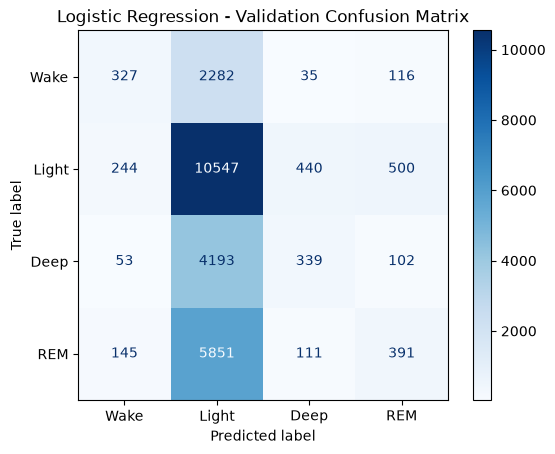

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=[0, 1, 2, 3],
    display_labels=["Wake", "Light", "Deep", "REM"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

# Random Forest

In [7]:
from sklearn.ensemble import RandomForestClassifier
import time

start = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Training completed!")
print(f"Training time: {time.time() - start:.2f} seconds")

Training completed!
Training time: 1.22 seconds


In [8]:
from sklearn.metrics import accuracy_score, classification_report

# Predict validation data
y_val_pred_rf = rf_model.predict(X_val)

# Calculate accuracy
accuracy_rf = accuracy_score(y_val, y_val_pred_rf)

print(f"Validation Accuracy: {accuracy_rf:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

Validation Accuracy: 41.47%

Classification Report:
              precision    recall  f1-score   support

        Wake       0.43      0.29      0.34      2760
       Light       0.48      0.63      0.54     11731
        Deep       0.26      0.10      0.15      4687
         REM       0.31      0.31      0.31      6498

    accuracy                           0.41     25676
   macro avg       0.37      0.33      0.34     25676
weighted avg       0.39      0.41      0.39     25676



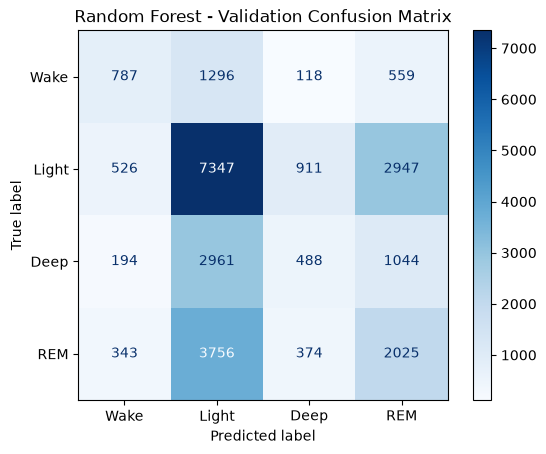

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_rf,
    labels=[0, 1, 2, 3],
    display_labels=["Wake", "Light", "Deep", "REM"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Validation Confusion Matrix")
plt.show()